# Multilingual controls for Voynich analysis

This notebook extends the CDEF + MI analysis to **8 corpora**:

| # | Corpus | Family | Source | Tokens |
|---|--------|--------|--------|--------|
| 1 | Voynich | (unknown) | STA1 2.0 | ~37,087 words |
| 2 | Latin | Indo-European / Italic | Vulgate (Gutenberg #8300) | subsampled |
| 3 | Caesar | Monoalphabetic cipher | ROT-13 on Latin | subsampled |
| 4 | Vigenere | Polyalphabetic cipher | key='voynich' on Latin | subsampled |
| 5 | Hebrew | Semitic | Torah / Sefaria-Export | subsampled |
| 6 | Arabic | Semitic | Quran / Tanzil | subsampled |
| 7 | Turkish | Agglutinative / Turkic | Wikipedia / Leipzig | subsampled |
| 8 | Finnish | Agglutinative / Uralic | Kalevala / Gutenberg #7000 | subsampled |

Analysis blocks: **C** (conditional entropy), **D** (spectral gap), **F** (curve shape), **MI** (positional + bigram).

In [1]:
# ── Cell 1: Imports + visual constants ──────────────────────────
import re, math, random, io, os, tarfile, json, warnings
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import requests
from tqdm.notebook import tqdm

warnings.filterwarnings('ignore')

# ── Colours for 8 corpora ───────────────────────────────────────────
COLOR_MAP = {
    'Voynich':  '#E53935',
    'Latin':    '#1E88E5',
    'Cesar':    '#43A047',
    'Vigenere': '#FB8C00',
    'Hebreo':   '#8E24AA',
    'Arabe':    '#00ACC1',
    'Turco':    '#6D4C41',
    'Fines':    '#D81B60',
}

MARKER_MAP = {
    'Voynich':  'o',
    'Latin':    's',
    'Cesar':    '^',
    'Vigenere': 'D',
    'Hebreo':   'v',
    'Arabe':    'P',
    'Turco':    'X',
    'Fines':    '*',
}

LW_MAP = {k: (3 if k == 'Voynich' else 2) for k in COLOR_MAP}

CORPUS_ORDER = ['Voynich', 'Latin', 'Cesar', 'Vigenere',
                'Hebreo', 'Arabe', 'Turco', 'Fines']

print('Imports OK')

Imports OK


In [2]:
# ── Cell 2: Reusable functions ──────────────────────────────────

# === From 03_entropy_spectral.ipynb ===

def parsear_sta_completo(filepath):
    """
    Full parser for STA1 2.0.
    Returns flat tokens with '.' as word separator.
    Produces 167 unique tokens and ~37,087 words.
    """
    tokens = []
    with open(filepath, 'r', encoding='utf-8') as f:
        for linea in f:
            linea = linea.strip()
            if not linea or linea.startswith('#'):
                continue
            if re.match(r'^<[^>]+>\s*<!', linea):
                continue
            match = re.match(r'^<[^>]+>\s+(.*)', linea)
            if not match:
                continue
            texto = match.group(1).strip()
            texto = re.sub(r'\{[^}]*\}', '', texto)
            texto = re.sub(r'<[^>]*>',   '', texto)
            texto = re.sub(r'-',          '.', texto)
            texto = texto.strip()
            if not texto:
                continue
            for palabra_raw in texto.split('.'):
                palabra_raw = palabra_raw.strip()
                if not palabra_raw:
                    continue
                glifos = re.findall(r'[A-Z][0-9a-z]', palabra_raw)
                if glifos:
                    tokens.extend(glifos)
                    tokens.append('.')
    return tokens


def tokens_a_palabras(tokens):
    palabras, actual = [], []
    for t in tokens:
        if t == '.':
            if actual:
                palabras.append(actual)
                actual = []
        else:
            actual.append(t)
    if actual:
        palabras.append(actual)
    return palabras


def entropia_condicional_n(corpus_plano, n, max_tokens=500_000):
    """
    H(token | n previous tokens) with Witten-Bell smoothing.
    """
    corpus = corpus_plano[:max_tokens]
    vocab  = sorted(set(corpus))
    V      = len(vocab)

    if n == 0:
        freq  = Counter(corpus)
        total = len(corpus)
        return -sum((c / total) * math.log2(c / total) for c in freq.values())

    ngram_counts  = Counter()
    nplus1_counts = Counter()

    for i in range(len(corpus) - n):
        ctx      = tuple(corpus[i:i + n])
        next_tok = corpus[i + n]
        ngram_counts[ctx] += 1
        nplus1_counts[(ctx, next_tok)] += 1

    total_ctx = sum(ngram_counts.values())
    H = 0.0

    for ctx, ctx_count in ngram_counts.items():
        p_ctx = ctx_count / total_ctx
        tipos_ctx = sum(1 for (c, _) in nplus1_counts if c == ctx)
        denom     = ctx_count + tipos_ctx
        if denom == 0:
            continue

        H_ctx = 0.0
        for tok in vocab:
            c = nplus1_counts.get((ctx, tok), 0)
            if c > 0:
                p = c / denom
            else:
                p = (tipos_ctx / denom) / V
            if p > 0:
                H_ctx -= p * math.log2(p)
        H += p_ctx * H_ctx

    return H


def construir_matriz_transicion(corpus_palabras):
    """
    Glyph-level Markov transition matrix.
    """
    corpus_plano = [g for p in corpus_palabras for g in p]
    tokens = sorted(set(corpus_plano))
    index  = {tok: i for i, tok in enumerate(tokens)}
    n      = len(tokens)

    M = np.zeros((n, n))
    for i in range(len(corpus_plano) - 1):
        r, c = index[corpus_plano[i]], index[corpus_plano[i + 1]]
        M[r, c] += 1

    row_sums = M.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1
    M = M / row_sums

    return M, tokens, index


def analisis_espectral(M, nombre, tokens=None):
    eigvals, eigvecs = np.linalg.eig(M)
    orden       = np.argsort(np.abs(eigvals))[::-1]
    eigvals_abs = np.abs(eigvals)[orden]
    eigvecs_ord = eigvecs[:, orden]

    lambda1 = eigvals_abs[0]
    lambda2 = eigvals_abs[1]
    gap     = lambda1 - lambda2
    t_mix   = 1.0 / gap if gap > 0 else np.inf

    print(f'\n{nombre}:')
    print(f'  Vocab size:  {M.shape[0]}')
    print(f'  \u03bb\u2081 = {lambda1:.6f}')
    print(f'  \u03bb\u2082 = {lambda2:.6f}')
    print(f'  Spectral gap \u03b4 = {gap:.4f}')
    print(f'  Mixing time \u2248 {t_mix:.1f} steps')

    if tokens is not None:
        vec2      = np.abs(eigvecs_ord[:, 1].real)
        vec2_norm = vec2 / vec2.sum()
        top5      = np.argsort(vec2_norm)[::-1][:5]
        top5_str  = ', '.join([f"{tokens[i]}({vec2_norm[i]:.3f})" for i in top5])
        print(f'  Top tokens in \u03bb\u2082: {top5_str}')

    return {
        'nombre': nombre, 'lambda1': lambda1, 'lambda2': lambda2,
        'gap': gap, 't_mix': t_mix, 'eigvals_abs': eigvals_abs
    }


def metricas_curva(nombre, vals, ordenes):
    """
    Computes metrics describing the geometry of the H_N curve.
    """
    h0      = vals[0]
    norm    = [v / h0 for v in vals]

    h_min   = min(vals)
    n_min   = ordenes[vals.index(h_min)]
    rebote  = vals[-1] - h_min

    pendiente_ini = (vals[0] - vals[1]) / vals[0]

    try:
        auc = np.trapezoid(norm, ordenes) / ordenes[-1]
    except AttributeError:
        auc = np.trapz(norm, ordenes) / ordenes[-1]

    return {
        'nombre':        nombre,
        'H0':            h0,
        'H_min':         h_min,
        'N_min':         n_min,
        'rebote':        rebote,
        'pendiente_ini': pendiente_ini,
        'AUC_norm':      auc,
    }


def cifrado_cesar(palabras, shift=13):
    """ROT-13: monoalphabetic substitution."""
    alfa  = 'abcdefghijklmnopqrstuvwxyz'
    tabla = {c: alfa[(i + shift) % 26] for i, c in enumerate(alfa)}
    return [[tabla.get(g, g) for g in p] for p in palabras]


def cifrado_vigenere(palabras, clave='voynich'):
    """Vigenere: polyalphabetic cipher."""
    alfa   = 'abcdefghijklmnopqrstuvwxyz'
    idx    = {c: i for i, c in enumerate(alfa)}
    shifts = [idx[c] for c in clave]
    resultado, k = [], 0
    for p in palabras:
        nueva = []
        for g in p:
            if g in idx:
                nueva.append(alfa[(idx[g] + shifts[k % len(shifts)]) % 26])
                k += 1
            else:
                nueva.append(g)
        resultado.append(nueva)
    return resultado


# === From 02_permutation_bootstrap.ipynb ===

def construir_tabla_tp(corpus):
    conteo_tp = defaultdict(int)
    conteo_t = defaultdict(int)
    conteo_p = defaultdict(int)
    total = 0
    for palabra in corpus:
        n = len(palabra)
        for i, token in enumerate(palabra):
            if i == 0:
                pos = "initial"
            elif i == n-1:
                pos = "final"
            else:
                pos = "middle"
            conteo_tp[(token, pos)] += 1
            conteo_t[token] += 1
            conteo_p[pos] += 1
            total += 1
    return conteo_tp, conteo_t, conteo_p, total


def mutual_information(corpus):
    conteo_tp, conteo_t, conteo_p, total = construir_tabla_tp(corpus)
    mi = 0.0
    for (token, pos), count_tp in conteo_tp.items():
        p_tp = count_tp / total
        p_t  = conteo_t[token] / total
        p_p  = conteo_p[pos] / total
        mi += p_tp * math.log(p_tp / (p_t * p_p), 2)
    return mi


def mutual_information_bigram(corpus):
    """Computes MI(Token_i ; Token_i+1)"""
    bigram_counts = Counter()
    unigram_counts = Counter()
    total_bigrams = 0
    total_tokens = 0
    for palabra in corpus:
        total_tokens += len(palabra)
        unigram_counts.update(palabra)
        for i in range(len(palabra) - 1):
            bigram = (palabra[i], palabra[i+1])
            bigram_counts[bigram] += 1
            total_bigrams += 1
    mi = 0.0
    for (t1, t2), count in bigram_counts.items():
        p_xy = count / total_bigrams
        p_x = unigram_counts[t1] / total_tokens
        p_y = unigram_counts[t2] / total_tokens
        mi += p_xy * math.log2(p_xy / (p_x * p_y))
    return mi


def permutar_intra_palabra(corpus, seed=None):
    rng = random.Random(seed)
    corpus_perm = []
    for palabra in corpus:
        if len(palabra) <= 1:
            corpus_perm.append(palabra.copy())
        else:
            nueva = palabra.copy()
            rng.shuffle(nueva)
            corpus_perm.append(nueva)
    return corpus_perm


def test_mi_global(corpus, n_perm=500):
    mi_obs = mutual_information(corpus)
    dist_perm = []
    for i in tqdm(range(n_perm), desc="Permuting MI"):
        corpus_perm = permutar_intra_palabra(corpus, seed=i)
        mi_perm = mutual_information(corpus_perm)
        dist_perm.append(mi_perm)
    dist_perm = np.array(dist_perm)
    p_valor = np.mean(dist_perm >= mi_obs)
    return {
        "mi_obs": mi_obs,
        "media_perm": dist_perm.mean(),
        "std_perm": dist_perm.std(),
        "p_valor": p_valor
    }


print('Functions loaded OK')

Functions loaded OK


In [3]:
# ── Cell 3: Load Voynich ──────────────────────────────────────────
STA_PATH = 'corpus/voynich_sta.txt'

tokens_voynich = parsear_sta_completo(STA_PATH)
palabras_voynich = tokens_a_palabras(tokens_voynich)
corpus_plano_voynich = [g for p in palabras_voynich for g in p]

N_VOYNICH = len(palabras_voynich)

print(f'Voynich: {N_VOYNICH:,} words, '
      f'{len(corpus_plano_voynich):,} tokens, '
      f'vocab = {len(set(corpus_plano_voynich))}')

Voynich: 37,087 words, 157,254 tokens, vocab = 166


In [4]:
# ── Cell 4: Download Vulgata + generate Caesar / Vigenere ────────────
print('Downloading Vulgata...')
url_vulgata = 'https://www.gutenberg.org/cache/epub/8300/pg8300.txt'
texto_latin = requests.get(url_vulgata, timeout=30).text

palabras_latin_raw = re.findall(r'[a-zA-Z]+', texto_latin.lower())
palabras_latin = [[c for c in p] for p in palabras_latin_raw if 2 <= len(p) <= 15]

# Subsample to N_VOYNICH words
latin_sub = palabras_latin[:N_VOYNICH]

# Generate ciphers on the Latin subsample
cesar_sub    = cifrado_cesar(latin_sub)
vigenere_sub = cifrado_vigenere(latin_sub)

print(f'Latin:    {len(latin_sub):,} words, vocab = {len(set(g for p in latin_sub for g in p))}')
print(f'Cesar:    {len(cesar_sub):,} words, vocab = {len(set(g for p in cesar_sub for g in p))}')
print(f'Vigenere: {len(vigenere_sub):,} words, vocab = {len(set(g for p in vigenere_sub for g in p))}')

Latin:    37,087 words, vocab = 26
Cesar:    37,087 words, vocab = 26
Vigenere: 37,087 words, vocab = 26


## New control corpora

**Why these 4 languages?**

- **Biblical Hebrew** and **Quranic Arabic**: Semitic languages with triconsonantal root morphology. If the Voynich encodes a Semitic language, it should show similar patterns in positional MI and entropy.
- **Turkish** and **Finnish**: agglutinative languages with productive prefix-root-suffix morphology. Their token structure could generate entropy curves with a shape similar to the Voynich.

All 4 languages operate at **character** level (not glyph), same as Latin/Caesar/Vigenere.

In [5]:
# ── Cell 6: Download Biblical Hebrew ────────────────────────────────
def descargar_hebreo():
    """Download Torah (5 books) from Sefaria-Export, strip nikkud."""
    libros = ['Genesis', 'Exodus', 'Leviticus', 'Numbers', 'Deuteronomy']
    base_url = ('https://raw.githubusercontent.com/Sefaria/Sefaria-Export/'
                'master/json/Tanakh/Torah/{}/Hebrew/Tanach%20with%20Text%20Only.json')
    
    todas_palabras = []
    for libro in libros:
        url = base_url.format(libro)
        print(f'  Downloading {libro}...')
        resp = requests.get(url, timeout=30)
        resp.raise_for_status()
        data = resp.json()
        
        # Structure: data['text'] is a list of chapters, each chapter a list of verses
        for capitulo in data['text']:
            for versiculo in capitulo:
                # Strip nikkud (vocalization marks)
                texto = re.sub(r'[\u0591-\u05C7]', '', versiculo)
                # Extract Hebrew consonants only
                palabras_heb = re.findall(r'[\u05D0-\u05EA]+', texto)
                for p in palabras_heb:
                    chars = list(p)
                    if 2 <= len(chars) <= 15:
                        todas_palabras.append(chars)
    
    print(f'  Hebrew total: {len(todas_palabras):,} words')
    return todas_palabras

print('Downloading Biblical Hebrew...')
palabras_hebreo_full = descargar_hebreo()

  Hebrew total: 80,051 words


In [6]:
# ── Cell 7: Download Quranic Arabic ────────────────────────────────
def descargar_arabe():
    """Download Quran from available GitHub sources, extract Arabic letters."""
    urls = [
        # Tanzil simple-plain via minijoomla mirror
        ('https://raw.githubusercontent.com/minijoomla/Tanzil/master/'
         'Packages/com_tanzil/site/resources/quran/quran-simple-plain.txt',
         'plain'),
        # amrayn no-tashkeel (plaintext without diacritics)
        ('https://raw.githubusercontent.com/amrayn/quran-text/main/'
         'quran-flat-no-tashkeel.txt',
         'flat'),
    ]
    
    texto = None
    for url, fmt in urls:
        print(f'  Trying {url.split("/")[-1]}...')
        try:
            resp = requests.get(url, timeout=30)
            resp.raise_for_status()
            texto = resp.text
            print(f'  OK ({len(texto):,} chars)')
            break
        except Exception as e:
            print(f'  Failed: {e}')
    
    if texto is None:
        raise RuntimeError('Could not download the Quran from any source')
    
    todas_palabras = []
    for linea in texto.splitlines():
        linea = linea.strip()
        if not linea or linea.startswith('#'):
            continue
        # Try to parse surah|ayah|text format
        partes = linea.split('|')
        if len(partes) >= 3:
            contenido = partes[2]
        else:
            contenido = linea
        # Strip Arabic tashkeel/diacritics (U+064B-U+065F, U+0670)
        contenido = re.sub(r'[\u064B-\u065F\u0670]', '', contenido)
        # Extract base Arabic letters only
        palabras_ar = re.findall(r'[\u0621-\u064A]+', contenido)
        for p in palabras_ar:
            chars = list(p)
            if 2 <= len(chars) <= 15:
                todas_palabras.append(chars)
    
    print(f'  Arabic total: {len(todas_palabras):,} words')
    return todas_palabras

print('Downloading Quranic Arabic...')
palabras_arabe_full = descargar_arabe()

  Trying quran-simple-plain.txt...
  OK (706,070 chars)
  Arabic total: 78,242 words


In [7]:
# ── Cell 8: Download Turkish ─────────────────────────────────────────
def descargar_turco():
    """Download Leipzig Turkish Wikipedia corpus."""
    url = ('https://downloads.wortschatz-leipzig.de/corpora/'
           'tur_wikipedia_2021_100K.tar.gz')
    print('  Downloading Turkish corpus (Leipzig)...')
    resp = requests.get(url, timeout=120)
    resp.raise_for_status()
    
    todas_palabras = []
    with tarfile.open(fileobj=io.BytesIO(resp.content), mode='r:gz') as tar:
        for member in tar.getmembers():
            if member.name.endswith('-sentences.txt'):
                f = tar.extractfile(member)
                if f is None:
                    continue
                texto = f.read().decode('utf-8')
                for linea in texto.splitlines():
                    # Format: id<tab>sentence
                    partes = linea.split('\t', 1)
                    if len(partes) < 2:
                        continue
                    oracion = partes[1].lower()
                    palabras_tr = re.findall(r'[a-z\u00e7\u015f\u011f\u0131\u00f6\u00fc]+', oracion)
                    for p in palabras_tr:
                        chars = list(p)
                        if 2 <= len(chars) <= 15:
                            todas_palabras.append(chars)
    
    print(f'  Turkish total: {len(todas_palabras):,} words')
    return todas_palabras

print('Downloading Turkish...')
palabras_turco_full = descargar_turco()

  Turkish total: 1,269,078 words


In [8]:
# ── Cell 9: Download Finnish ─────────────────────────────────────────
def descargar_fines():
    """Download Kalevala from Project Gutenberg."""
    url = 'https://www.gutenberg.org/cache/epub/7000/pg7000.txt'
    print('  Downloading Kalevala...')
    resp = requests.get(url, timeout=30)
    resp.raise_for_status()
    
    todas_palabras = []
    texto = resp.text.lower()
    palabras_fi = re.findall(r'[a-z\u00e4\u00f6]+', texto)
    for p in palabras_fi:
        chars = list(p)
        if 2 <= len(chars) <= 15:
            todas_palabras.append(chars)
    
    print(f'  Finnish total: {len(todas_palabras):,} words')
    return todas_palabras

print('Downloading Finnish...')
palabras_fines_full = descargar_fines()

  Finnish total: 71,194 words


In [9]:
# ── Cell 10: Unified assembly ───────────────────────────────────
# Subsample all to N_VOYNICH words (deterministic: first N)
hebreo_sub  = palabras_hebreo_full[:N_VOYNICH]
arabe_sub   = palabras_arabe_full[:N_VOYNICH]
turco_sub   = palabras_turco_full[:N_VOYNICH]
fines_sub   = palabras_fines_full[:N_VOYNICH]

# Unified dictionaries
ALL_WORDS = {
    'Voynich':  palabras_voynich,
    'Latin':    latin_sub,
    'Cesar':    cesar_sub,
    'Vigenere': vigenere_sub,
    'Hebreo':   hebreo_sub,
    'Arabe':    arabe_sub,
    'Turco':    turco_sub,
    'Fines':    fines_sub,
}

ALL_FLAT = {name: [g for p in words for g in p] for name, words in ALL_WORDS.items()}

# Summary table
print(f'{"Corpus":<12} {"Words":>10} {"Tokens":>10} {"Vocab":>8} {"Avg Length":>12}')
print('-' * 56)
for name in CORPUS_ORDER:
    words = ALL_WORDS[name]
    flat  = ALL_FLAT[name]
    vocab = len(set(flat))
    mean_len = np.mean([len(p) for p in words])
    print(f'{name:<12} {len(words):>10,} {len(flat):>10,} {vocab:>8} {mean_len:>12.2f}')

Corpus            Words     Tokens    Vocab   Avg Length
--------------------------------------------------------
Voynich          37,087    157,254      166         4.24
Latin            37,087    152,954       26         4.12
Cesar            37,087    152,954       26         4.12
Vigenere         37,087    152,954       26         4.12
Hebreo           37,087    140,754       27         3.80
Arabe            37,087    158,074       36         4.26
Turco            37,087    230,915       32         6.23
Fines            37,087    244,893       26         6.60


## Block C: Conditional entropy

We compute $H(X_n | X_{n-1}, \ldots, X_{n-N})$ for $N = 0, 1, 2, 3, 4$ with Witten-Bell smoothing.

The **decay rate** indicates how much sequential structure each corpus has: natural languages decay strongly, ciphers weakly.

In [10]:
# ── Cell 12: Compute H0-H4 for all 8 corpora ─────────────────────
ordenes = [0, 1, 2, 3, 4]
H_curves = {}

for name in CORPUS_ORDER:
    flat = ALL_FLAT[name]
    print(f'Computing entropy {name} ({len(flat):,} tokens)...')
    vals = []
    for n in ordenes:
        h = entropia_condicional_n(flat, n)
        vals.append(h)
        print(f'  H{n} = {h:.4f}')
    H_curves[name] = vals
    print()

Computing entropy Voynich (157,254 tokens)...
  H0 = 4.1408
  H1 = 2.9608
  H2 = 2.9898
  H3 = 3.3165
  H4 = 3.7739

Computing entropy Latin (152,954 tokens)...
  H0 = 4.1214
  H1 = 3.4630
  H2 = 2.9511
  H3 = 2.5930
  H4 = 2.4659

Computing entropy Cesar (152,954 tokens)...
  H0 = 4.1214
  H1 = 3.4630
  H2 = 2.9511
  H3 = 2.5930
  H4 = 2.4659

Computing entropy Vigenere (152,954 tokens)...
  H0 = 4.6140
  H1 = 4.3239
  H2 = 3.5940
  H3 = 3.1157
  H4 = 2.8953

Computing entropy Hebreo (140,754 tokens)...
  H0 = 4.2302
  H1 = 3.8846
  H2 = 3.3792
  H3 = 3.0772
  H4 = 2.9642

Computing entropy Arabe (158,074 tokens)...
  H0 = 4.3698
  H1 = 3.9223
  H2 = 3.3614
  H3 = 3.0295
  H4 = 2.9116

Computing entropy Turco (230,915 tokens)...
  H0 = 4.3505
  H1 = 3.7456
  H2 = 3.2649
  H3 = 2.9562
  H4 = 2.8631

Computing entropy Fines (244,893 tokens)...
  H0 = 3.9540
  H1 = 3.4477
  H2 = 3.1253
  H3 = 2.8485
  H4 = 2.7460



In [11]:
# ── Cell 13: Summary table with decay % ────────────────────────
print(f'{"Corpus":<12} {"H0":>8} {"H1":>8} {"H2":>8} {"H3":>8} {"H4":>8} {"Decay%":>8}')
print('-' * 64)
for name in CORPUS_ORDER:
    vals = H_curves[name]
    decay = (vals[0] - vals[-1]) / vals[0] * 100
    row = ' '.join(f'{v:>8.3f}' for v in vals)
    print(f'{name:<12} {row} {decay:>7.1f}%')

Corpus             H0       H1       H2       H3       H4   Decay%
----------------------------------------------------------------
Voynich         4.141    2.961    2.990    3.317    3.774     8.9%
Latin           4.121    3.463    2.951    2.593    2.466    40.2%
Cesar           4.121    3.463    2.951    2.593    2.466    40.2%
Vigenere        4.614    4.324    3.594    3.116    2.895    37.3%
Hebreo          4.230    3.885    3.379    3.077    2.964    29.9%
Arabe           4.370    3.922    3.361    3.030    2.912    33.4%
Turco           4.351    3.746    3.265    2.956    2.863    34.2%
Fines           3.954    3.448    3.125    2.849    2.746    30.6%


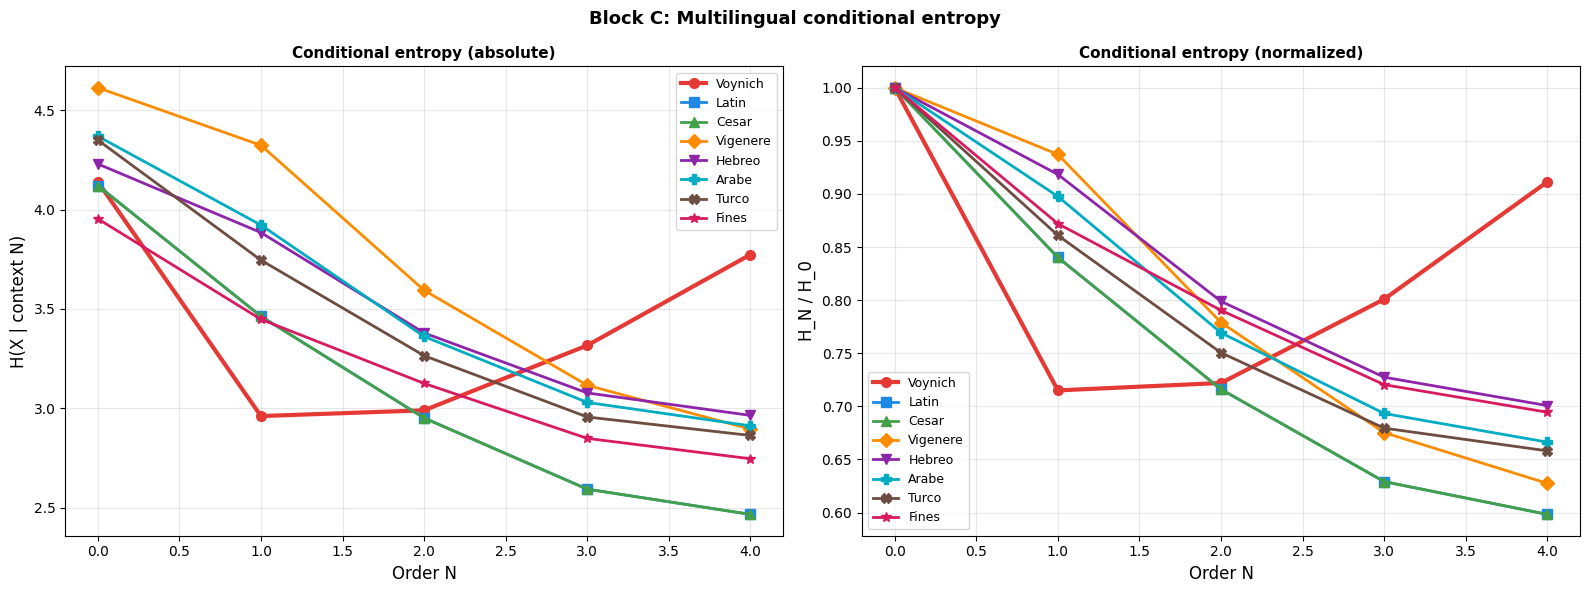

Saved: bloque_C_multilingue.png


In [12]:
# ── Cell 14: Visualisation Block C ─────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Panel 1: Absolute values
for name in CORPUS_ORDER:
    vals = H_curves[name]
    ax1.plot(ordenes, vals, color=COLOR_MAP[name], marker=MARKER_MAP[name],
             lw=LW_MAP[name], markersize=7, label=name)
ax1.set_xlabel('Order N', fontsize=12)
ax1.set_ylabel('H(X | context N)', fontsize=12)
ax1.set_title('Conditional entropy (absolute)', fontsize=11, fontweight='bold')
ax1.legend(fontsize=9)
ax1.grid(True, alpha=0.3)

# Panel 2: Normalised by H0
for name in CORPUS_ORDER:
    vals = H_curves[name]
    norm = [v / vals[0] for v in vals]
    ax2.plot(ordenes, norm, color=COLOR_MAP[name], marker=MARKER_MAP[name],
             lw=LW_MAP[name], markersize=7, label=name)
ax2.set_xlabel('Order N', fontsize=12)
ax2.set_ylabel('H_N / H_0', fontsize=12)
ax2.set_title('Conditional entropy (normalized)', fontsize=11, fontweight='bold')
ax2.legend(fontsize=9)
ax2.grid(True, alpha=0.3)

fig.suptitle('Block C: Multilingual conditional entropy', fontsize=13, fontweight='bold')
plt.tight_layout()
fig.savefig('images/bloque_C_multilingue.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: bloque_C_multilingue.png')

## Block D: Spectral gap

We build the character/glyph-level Markov transition matrix and compute the **spectral gap** $\delta = \lambda_1 - \lambda_2$.

A large gap indicates fast mixing (little structure); a small gap indicates strongly connected token clusters.

In [13]:
# ── Cell 16: Build matrices + spectral analysis ────────────────
spectral_results = {}

for name in CORPUS_ORDER:
    words = ALL_WORDS[name]
    M, toks, idx = construir_matriz_transicion(words)
    res = analisis_espectral(M, name, tokens=toks)
    spectral_results[name] = res


Voynich:
  Vocab size:  166
  λ₁ = 1.000000
  λ₂ = 0.459422
  Spectral gap δ = 0.5406
  Mixing time ≈ 1.8 steps
  Top tokens in λ₂: Ys(0.114), Yp(0.049), Yn(0.019), Xd(0.018), Tf(0.017)

Latin:
  Vocab size:  26
  λ₁ = 1.000000
  λ₂ = 0.341741
  Spectral gap δ = 0.6583
  Mixing time ≈ 1.5 steps
  Top tokens in λ₂: j(0.086), v(0.080), t(0.077), h(0.073), z(0.071)

Cesar:
  Vocab size:  26
  λ₁ = 1.000000
  λ₂ = 0.341741
  Spectral gap δ = 0.6583
  Mixing time ≈ 1.5 steps
  Top tokens in λ₂: w(0.086), i(0.080), g(0.077), u(0.073), m(0.071)

Vigenere:
  Vocab size:  26
  λ₁ = 1.000000
  λ₂ = 0.147940
  Spectral gap δ = 0.8521
  Mixing time ≈ 1.2 steps
  Top tokens in λ₂: h(0.102), r(0.077), a(0.070), f(0.066), q(0.066)

Hebreo:
  Vocab size:  27
  λ₁ = 1.000000
  λ₂ = 0.188027
  Spectral gap δ = 0.8120
  Mixing time ≈ 1.2 steps
  Top tokens in λ₂: ץ(0.104), ך(0.074), ם(0.073), כ(0.061), ס(0.055)

Arabe:
  Vocab size:  36
  λ₁ = 1.000000
  λ₂ = 0.202468
  Spectral gap δ = 0.7975
  Mixing 

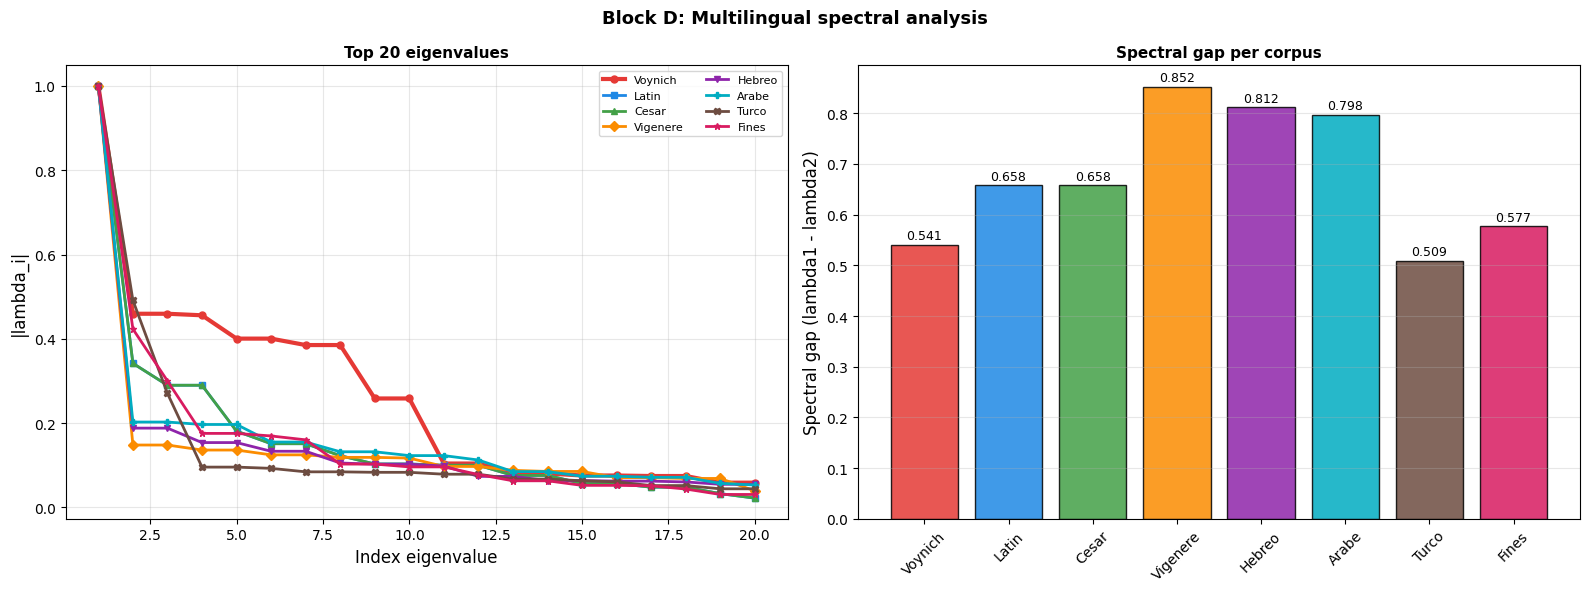

Saved: bloque_D_multilingue.png


In [14]:
# ── Cell 17: Visualisation Block D ─────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Panel 1: Top eigenvalues
n_eig = 20
for name in CORPUS_ORDER:
    eigs = spectral_results[name]['eigvals_abs'][:n_eig]
    ax1.plot(range(1, n_eig + 1), eigs, color=COLOR_MAP[name],
             marker=MARKER_MAP[name], lw=LW_MAP[name], markersize=5, label=name)
ax1.set_xlabel('Index eigenvalue', fontsize=12)
ax1.set_ylabel('|lambda_i|', fontsize=12)
ax1.set_title('Top 20 eigenvalues', fontsize=11, fontweight='bold')
ax1.legend(fontsize=8, ncol=2)
ax1.grid(True, alpha=0.3)

# Panel 2: Spectral gap bars
gaps = [spectral_results[name]['gap'] for name in CORPUS_ORDER]
colors = [COLOR_MAP[name] for name in CORPUS_ORDER]
bars = ax2.bar(CORPUS_ORDER, gaps, color=colors, alpha=0.85, edgecolor='black')
ax2.set_ylabel('Spectral gap (lambda1 - lambda2)', fontsize=12)
ax2.set_title('Spectral gap per corpus', fontsize=11, fontweight='bold')
ax2.tick_params(axis='x', rotation=45)
ax2.grid(True, alpha=0.3, axis='y')

# Annotate values
for bar, val in zip(bars, gaps):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
             f'{val:.3f}', ha='center', va='bottom', fontsize=9)

fig.suptitle('Block D: Multilingual spectral analysis', fontsize=13, fontweight='bold')
plt.tight_layout()
fig.savefig('images/bloque_D_multilingue.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: bloque_D_multilingue.png')

## Block F: Curve shape

The key question: **does any natural language show the Voynich "U" shape?**

The Voynich has a peculiar entropy curve shape: it drops, reaches a minimum, and then **bounces** back up. This pattern does not appear in Latin or in ciphers. We compare with Semitic and agglutinative languages.

In [15]:
# ── Cell 19: Compute curve shape metrics ─────────────────────────────
curva_results = {}

for name in CORPUS_ORDER:
    vals = H_curves[name]
    res = metricas_curva(name, vals, ordenes)
    curva_results[name] = res

# Summary table
print(f'{"Corpus":<12} {"H0":>7} {"H_min":>7} {"N_min":>6} {"Bounce":>8} {"Init_slope":>9} {"AUC":>7}')
print('-' * 62)
for name in CORPUS_ORDER:
    r = curva_results[name]
    print(f'{name:<12} {r["H0"]:>7.3f} {r["H_min"]:>7.3f} {r["N_min"]:>6d} '
          f'{r["rebote"]:>8.4f} {r["pendiente_ini"]:>9.4f} {r["AUC_norm"]:>7.4f}')

Corpus            H0   H_min  N_min   Bounce Init_slope     AUC
--------------------------------------------------------------
Voynich        4.141   2.961      1   0.8131    0.2850  0.7984
Latin          4.121   2.466      4   0.0000    0.1597  0.7462
Cesar          4.121   2.466      4   0.0000    0.1597  0.7462
Vigenere       4.614   2.895      4   0.0000    0.0629  0.8013
Hebreo         4.230   2.964      4   0.0000    0.0817  0.8237
Arabe          4.370   2.912      4   0.0000    0.1024  0.7983
Turco          4.351   2.863      4   0.0000    0.1390  0.7800
Fines          3.954   2.746      4   0.0000    0.1280  0.8075


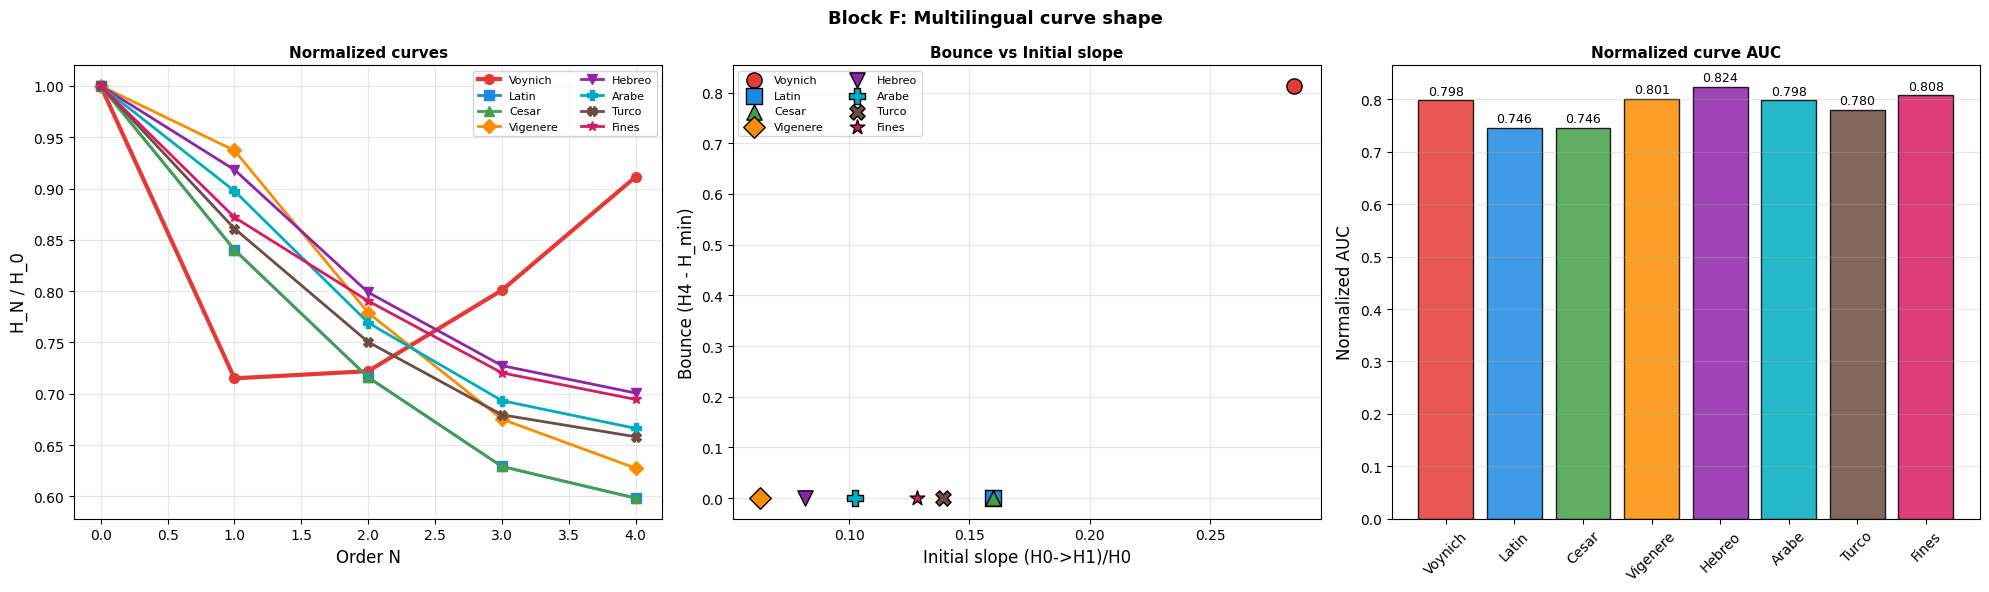

Saved: bloque_F_multilingue.png


In [16]:
# ── Cell 20: Visualisation Block F ─────────────────────────────────
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 6))

# Panel 1: Normalized curves
for name in CORPUS_ORDER:
    vals = H_curves[name]
    norm = [v / vals[0] for v in vals]
    ax1.plot(ordenes, norm, color=COLOR_MAP[name], marker=MARKER_MAP[name],
             lw=LW_MAP[name], markersize=7, label=name)
ax1.set_xlabel('Order N', fontsize=12)
ax1.set_ylabel('H_N / H_0', fontsize=12)
ax1.set_title('Normalized curves', fontsize=11, fontweight='bold')
ax1.legend(fontsize=8, ncol=2)
ax1.grid(True, alpha=0.3)

# Panel 2: Scatter bounce vs initial slope
for name in CORPUS_ORDER:
    r = curva_results[name]
    ax2.scatter(r['pendiente_ini'], r['rebote'], color=COLOR_MAP[name],
                marker=MARKER_MAP[name], s=120, label=name, edgecolors='black', zorder=5)
ax2.set_xlabel('Initial slope (H0->H1)/H0', fontsize=12)
ax2.set_ylabel('Bounce (H4 - H_min)', fontsize=12)
ax2.set_title('Bounce vs Initial slope', fontsize=11, fontweight='bold')
ax2.legend(fontsize=8, ncol=2)
ax2.grid(True, alpha=0.3)

# Panel 3: AUC bars
aucs = [curva_results[name]['AUC_norm'] for name in CORPUS_ORDER]
colors = [COLOR_MAP[name] for name in CORPUS_ORDER]
bars = ax3.bar(CORPUS_ORDER, aucs, color=colors, alpha=0.85, edgecolor='black')
ax3.set_ylabel('Normalized AUC', fontsize=12)
ax3.set_title('Normalized curve AUC', fontsize=11, fontweight='bold')
ax3.tick_params(axis='x', rotation=45)
ax3.grid(True, alpha=0.3, axis='y')
for bar, val in zip(bars, aucs):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
             f'{val:.3f}', ha='center', va='bottom', fontsize=9)

fig.suptitle('Block F: Multilingual curve shape', fontsize=13, fontweight='bold')
plt.tight_layout()
fig.savefig('images/bloque_F_multilingue.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: bloque_F_multilingue.png')

## MI analysis: Positional + bigram Mutual Information

- **Positional MI**: $I(Token; Position)$ where position = {initial, middle, final}. Measures how much a token's identity depends on its position within the word.
- **Bigram MI**: $I(Token_i; Token_{i+1})$. Measures the dependency between adjacent tokens.

Intra-word permutation test to assess statistical significance.

In [17]:
# ── Cell 22: Compute positional MI + bigram MI ───────────────────────
mi_pos_results = {}
mi_big_results = {}

for name in CORPUS_ORDER:
    words = ALL_WORDS[name]
    mi_p = mutual_information(words)
    mi_b = mutual_information_bigram(words)
    mi_pos_results[name] = mi_p
    mi_big_results[name] = mi_b
    print(f'{name:<12}  MI_pos = {mi_p:.4f} bits    MI_bigram = {mi_b:.4f} bits')

Voynich       MI_pos = 0.6578 bits    MI_bigram = 1.6811 bits
Latin         MI_pos = 0.2672 bits    MI_bigram = 1.0817 bits
Cesar         MI_pos = 0.2672 bits    MI_bigram = 1.0817 bits
Vigenere      MI_pos = 0.0533 bits    MI_bigram = 0.4425 bits
Hebreo        MI_pos = 0.3113 bits    MI_bigram = 0.6069 bits
Arabe         MI_pos = 0.2340 bits    MI_bigram = 0.7488 bits
Turco         MI_pos = 0.1505 bits    MI_bigram = 0.8346 bits
Fines         MI_pos = 0.2053 bits    MI_bigram = 0.6520 bits


In [18]:
# ── Cell 23: MI permutation test ─────────────────────────────────
# For Voynich + 4 new languages
test_corpora = ['Voynich', 'Hebreo', 'Arabe', 'Turco', 'Fines']
mi_test_results = {}

for name in test_corpora:
    print(f'\nPermutation test for {name}...')
    words = ALL_WORDS[name]
    res = test_mi_global(words, n_perm=200)
    mi_test_results[name] = res
    print(f'  MI_obs = {res["mi_obs"]:.4f}, media_perm = {res["media_perm"]:.4f}, '
          f'std = {res["std_perm"]:.4f}, p = {res["p_valor"]:.4f}')


Permutation test for Voynich...


Permuting MI:   0%|          | 0/200 [00:00<?, ?it/s]

  MI_obs = 0.6578, media_perm = 0.0079, std = 0.0003, p = 0.0000

Permutation test for Hebreo...


Permuting MI:   0%|          | 0/200 [00:00<?, ?it/s]

  MI_obs = 0.3113, media_perm = 0.0078, std = 0.0004, p = 0.0000

Permutation test for Arabe...


Permuting MI:   0%|          | 0/200 [00:00<?, ?it/s]

  MI_obs = 0.2340, media_perm = 0.0071, std = 0.0003, p = 0.0000

Permutation test for Turco...


Permuting MI:   0%|          | 0/200 [00:00<?, ?it/s]

  MI_obs = 0.1505, media_perm = 0.0053, std = 0.0002, p = 0.0000

Permutation test for Fines...


Permuting MI:   0%|          | 0/200 [00:00<?, ?it/s]

  MI_obs = 0.2053, media_perm = 0.0016, std = 0.0001, p = 0.0000


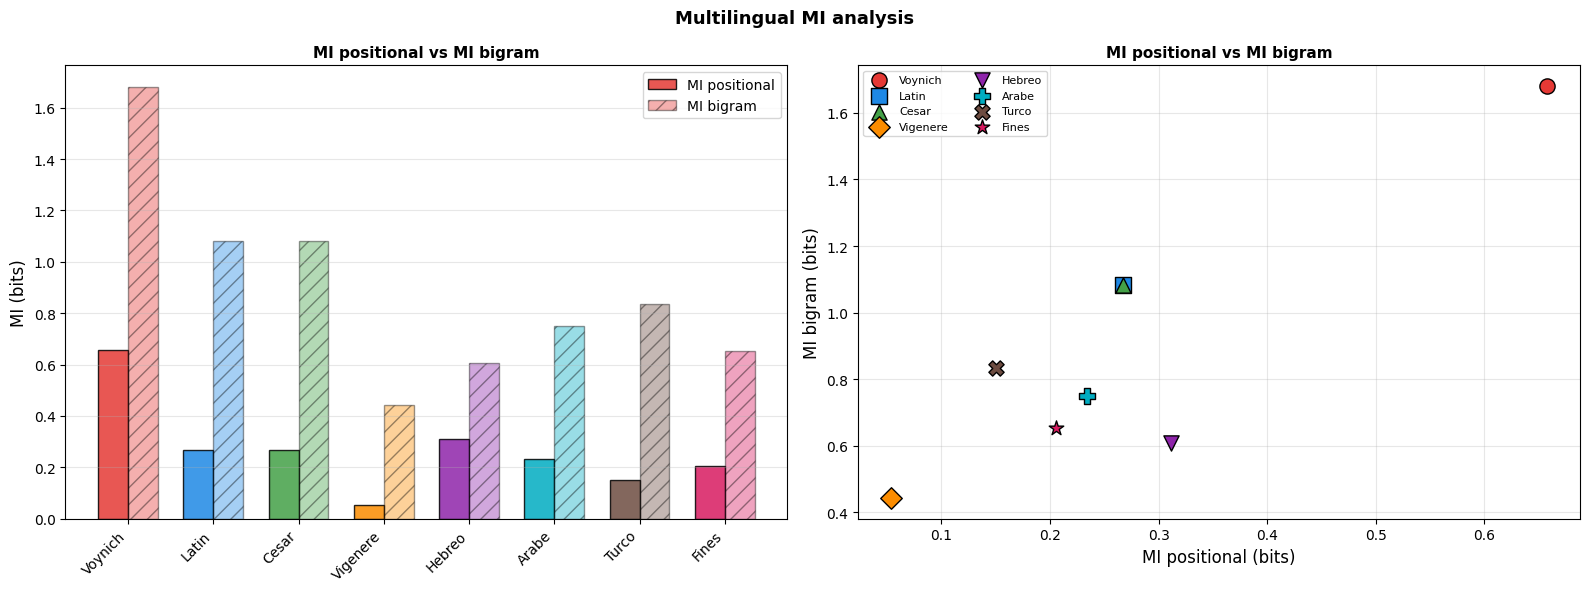

Saved: mi_multilingue.png


In [19]:
# ── Cell 24: MI Visualisation ───────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Panel 1: Grouped bars for MI_pos and MI_bigram
x = np.arange(len(CORPUS_ORDER))
width = 0.35
vals_pos = [mi_pos_results[name] for name in CORPUS_ORDER]
vals_big = [mi_big_results[name] for name in CORPUS_ORDER]
colors_bar = [COLOR_MAP[name] for name in CORPUS_ORDER]

bars1 = ax1.bar(x - width/2, vals_pos, width, label='MI positional',
                color=colors_bar, alpha=0.85, edgecolor='black')
bars2 = ax1.bar(x + width/2, vals_big, width, label='MI bigram',
                color=colors_bar, alpha=0.4, edgecolor='black', hatch='//')
ax1.set_xticks(x)
ax1.set_xticklabels(CORPUS_ORDER, rotation=45, ha='right')
ax1.set_ylabel('MI (bits)', fontsize=12)
ax1.set_title('MI positional vs MI bigram', fontsize=11, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3, axis='y')

# Panel 2: Scatter MI_pos vs MI_bigram
for name in CORPUS_ORDER:
    ax2.scatter(mi_pos_results[name], mi_big_results[name],
                color=COLOR_MAP[name], marker=MARKER_MAP[name],
                s=120, label=name, edgecolors='black', zorder=5)
ax2.set_xlabel('MI positional (bits)', fontsize=12)
ax2.set_ylabel('MI bigram (bits)', fontsize=12)
ax2.set_title('MI positional vs MI bigram', fontsize=11, fontweight='bold')
ax2.legend(fontsize=8, ncol=2)
ax2.grid(True, alpha=0.3)

fig.suptitle('Multilingual MI analysis', fontsize=13, fontweight='bold')
plt.tight_layout()
fig.savefig('images/mi_multilingue.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: mi_multilingue.png')

In [20]:
# ── Cell 25: Complete scorecard ─────────────────────────────────────
print('=' * 90)
print('MULTILINGUAL SCORECARD')
print('=' * 90)
print(f'{"Corpus":<12} {"H0":>7} {"Decay%":>8} {"Gap":>7} {"Bounce":>8} {"AUC":>7} '
      f'{"MI_pos":>8} {"MI_big":>8}')
print('-' * 90)

for name in CORPUS_ORDER:
    h_vals = H_curves[name]
    decay  = (h_vals[0] - h_vals[-1]) / h_vals[0] * 100
    gap    = spectral_results[name]['gap']
    rebote = curva_results[name]['rebote']
    auc    = curva_results[name]['AUC_norm']
    mi_p   = mi_pos_results[name]
    mi_b   = mi_big_results[name]
    
    print(f'{name:<12} {h_vals[0]:>7.3f} {decay:>7.1f}% {gap:>7.4f} '
          f'{rebote:>8.4f} {auc:>7.4f} {mi_p:>8.4f} {mi_b:>8.4f}')

print('=' * 90)

MULTILINGUAL SCORECARD
Corpus            H0   Decay%     Gap   Bounce     AUC   MI_pos   MI_big
------------------------------------------------------------------------------------------
Voynich        4.141     8.9%  0.5406   0.8131  0.7984   0.6578   1.6811
Latin          4.121    40.2%  0.6583   0.0000  0.7462   0.2672   1.0817
Cesar          4.121    40.2%  0.6583   0.0000  0.7462   0.2672   1.0817
Vigenere       4.614    37.3%  0.8521   0.0000  0.8013   0.0533   0.4425
Hebreo         4.230    29.9%  0.8120   0.0000  0.8237   0.3113   0.6069
Arabe          4.370    33.4%  0.7975   0.0000  0.7983   0.2340   0.7488
Turco          4.351    34.2%  0.5088   0.0000  0.7800   0.1505   0.8346
Fines          3.954    30.6%  0.5769   0.0000  0.8075   0.2053   0.6520


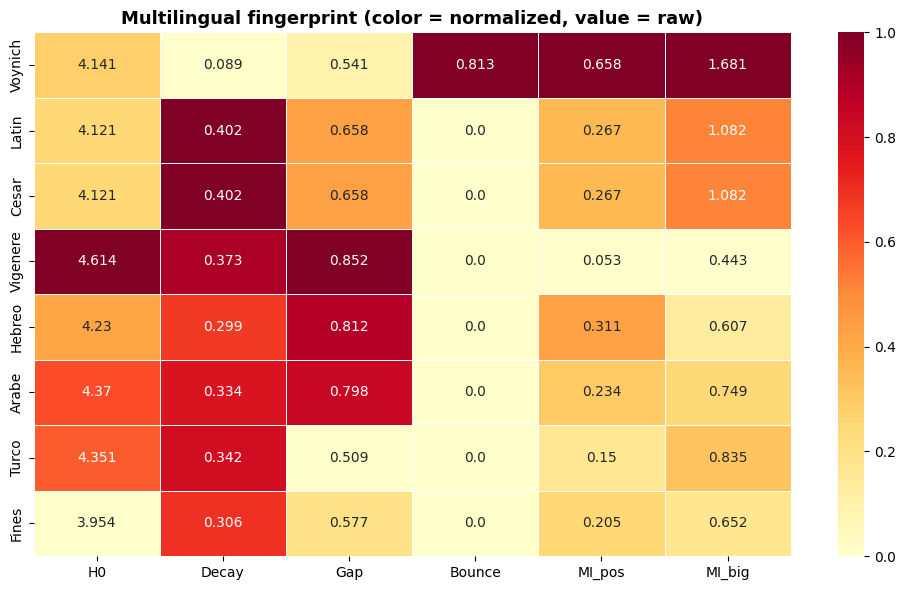

Saved: fingerprint_multilingue.png


In [21]:
# ── Cell 26: Heatmap fingerprint ────────────────────────────────────
# Build dataframe with 6 normalized metrics 0-1
metricas_raw = {}
for name in CORPUS_ORDER:
    h_vals = H_curves[name]
    decay  = (h_vals[0] - h_vals[-1]) / h_vals[0]
    metricas_raw[name] = {
        'H0':       h_vals[0],
        'Decay':    decay,
        'Gap':      spectral_results[name]['gap'],
        'Bounce':   curva_results[name]['rebote'],
        'MI_pos':   mi_pos_results[name],
        'MI_big':   mi_big_results[name],
    }

df_raw = pd.DataFrame(metricas_raw).T
df_raw = df_raw.loc[CORPUS_ORDER]

# Normalise each column min-max to [0, 1]
df_norm = (df_raw - df_raw.min()) / (df_raw.max() - df_raw.min())

# Heatmap
fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(df_norm, annot=df_raw.round(3).values, fmt='', cmap='YlOrRd',
            vmin=0, vmax=1.0, linewidths=0.5, ax=ax,
            xticklabels=df_norm.columns, yticklabels=df_norm.index)
ax.set_title('Multilingual fingerprint (color = normalized, value = raw)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
fig.savefig('images/fingerprint_multilingue.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: fingerprint_multilingue.png')

## Conclusions

### 1. Conditional entropy (Block C): The Voynich is an anomalous case

The Voynich has a decay of only **8.9%**, while **all** natural languages (including Semitic and agglutinative) decay between 30-40%. This rules out the hypothesis that low decay could be a typological feature of agglutinative or Semitic languages. It is not.

The normalised Voynich curve is unmistakable: it drops from 1.0 to ~0.71 at H1, then **rises** to ~0.91 at H4. None of the 6 natural languages does this — they all decrease monotonically.

**Interpretation**: Context beyond 1 token *destroys* predictability in the Voynich instead of adding it. This is incompatible with any known natural language, where more context always helps predict the next character.

### 2. Spectral gap (Block D): The Voynich clusters with agglutinative languages

The Voynich spectral gap (0.54) is nearly identical to Turkish (0.51) and close to Finnish (0.58). These three form a clear cluster, separated from Semitic languages (Hebrew 0.81, Arabic 0.80) and Vigenère (0.85).

**Interpretation**: A low gap indicates strongly connected token clusters that do not mix easily. In Turkish and Finnish this reflects agglutinative morphology: certain characters "live together" in suffixes and roots. That the Voynich shows this pattern suggests its glyph system has a comparable **internal modular structure**. In turn, Vigenère has the highest gap (0.85) because the polyalphabetic cipher destroys the clusters — confirming that the Voynich **does not behave like a polyalphabetic cipher**.

### 3. Curve shape (Block F): The bounce is unique

The Voynich bounce (0.813 bits, with minimum at N=1) is **absolutely unique**. All 6 natural languages and both ciphers have bounce = 0, with minimum at N=4 (the curve descends to the end). The Voynich is completely isolated in the bounce vs initial slope scatter: it has **both** the strongest initial slope (0.285) and the only non-zero bounce.

**Interpretation**: No typological family (Semitic, agglutinative, Italic) produces this pattern. The "U" is not an artefact of language type. This strongly reinforces the hypothesis that the Voynich has a **different generative mechanism** than a directly written natural language.

### 4. Mutual Information: The Voynich is an extreme outlier

- **Positional MI = 0.658 bits**: Voynich glyphs have a positional preference **twice as strong** as the most positionally dependent natural language (Hebrew, 0.311). Certain glyphs appear *almost exclusively* at the beginning, others in the middle, others at the end — beyond what any natural morphology produces.
- **Bigram MI = 1.681 bits**: Dependencies between adjacent glyphs are **60% stronger** than in Latin (1.082), the highest natural language. Voynich glyphs are extremely conditioned by their immediate neighbour.
- In the MI_pos vs MI_big scatter, the Voynich is **completely isolated** in the upper-right corner. All natural languages form a compact cluster.
- **Permutation test**: p = 0.000 for all corpora, confirming the positional preferences are real, not artefacts.

### 5. Synthesis: The Voynich fingerprint

| Metric | Voynich vs natural languages |
|--------|------------------------------|
| Decay | **Minimum** (0.089 vs 0.30-0.40) |
| Bounce | **Only non-zero** (0.813) |
| Gap | Similar to agglutinative (~0.54) |
| MI_pos | **Absolute maximum** (2x the next) |
| MI_big | **Absolute maximum** (1.6x the next) |

1. **Not a directly written natural language**. The 8.9% decay, the bounce, and the extreme MI values are incompatible with any tested language family. Semitic and agglutinative languages, the most plausible candidates, behave like all other natural languages.
2. **Not a simple cipher**. The low spectral gap (like agglutinative languages) and the very high positional MI are incompatible with substitution ciphers. A cipher would preserve Latin entropy but destroy positional structure (as Vigenère does).
3. **The generative mechanism has internal modular structure**. The combination of extreme positional MI + low gap + entropy bounce suggests a system where "pieces" (prefixes, roots, suffixes) combine with very rigid rules, **more rigid than any natural morphology**. This is consistent with an encoding table or an abbreviation system where positions within the "word" have fixed functions.
4. **The strongest clue**: The only feature where the Voynich resembles natural languages is the spectral gap (cluster with Turkish/Finnish). This suggests that, whatever it is, its structure *at the level of local glyph transitions* does have the modularity of an agglutinative language. But its behaviour at longer scales (context 2+) diverges completely.